The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


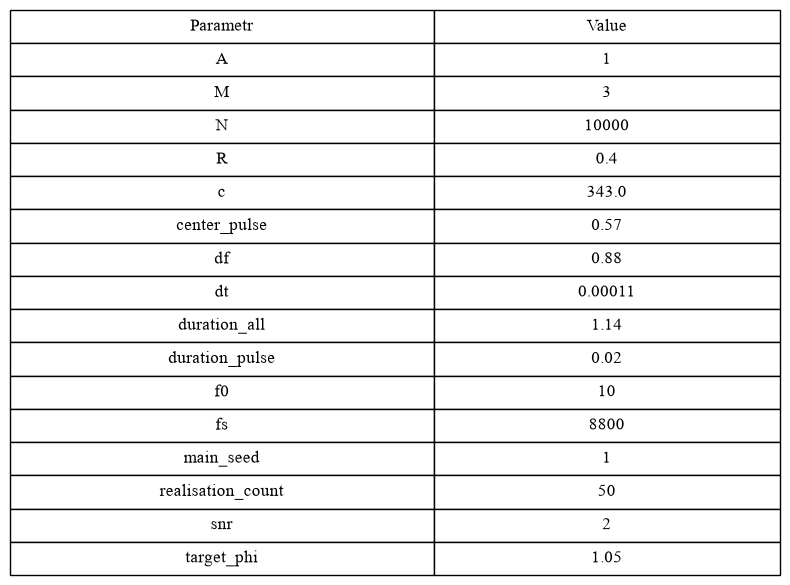

In [67]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import src.configs.config as cfg
import src.configs.comon as comon
import os
from src.plotting import create_and_save_table, create_config_table
from src.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       calculate_bartlett_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       calculate_stiring_matrix, 
                       get_est_phi,
                       calculate_capon_values,
                       calculate_fft, 
                       calculate_f_rms, 
                       filtering_spectrum, 
                       calculate_ifft, 
                       calculate_noise_level)

config_parametrs = cfg.init_rng()
path = "attachment/images/notebook"
os.makedirs(path,exist_ok=True)

create_config_table(config_parametrs)

In [68]:
#sin_signal = get_sin_signal(config_parametrs)
pulse_signal = get_impulse_signal(config_parametrs)
energy_pulse_value = calculate_energy(pulse_signal, config_parametrs["time_vector"])


In [69]:
sin_signal = get_sin_signal(config_parametrs)

pulse_signal = get_impulse_signal(config_parametrs)
pulse_signal_copy = pulse_signal.copy()
energy_pulse_value = calculate_energy(pulse_signal_copy, config_parametrs["time_vector"])

spectrum_signal = calculate_fft(pulse_signal_copy)
f_rms_betta = calculate_f_rms(spectrum_signal, config_parametrs)
en_signal = calculate_energy(pulse_signal, config_parametrs["time_vector"])

K = 0.5
B = K*f_rms_betta
width_rms = K*f_rms_betta
spectrum_filtering_signal = filtering_spectrum(spectrum_signal, B, config_parametrs["fs"])

back_signal = calculate_ifft(spectrum_filtering_signal)
energy_filt_pulse_value = calculate_energy(back_signal, config_parametrs["time_vector"])
f_rms_new = calculate_f_rms(calculate_fft(back_signal),config_parametrs)



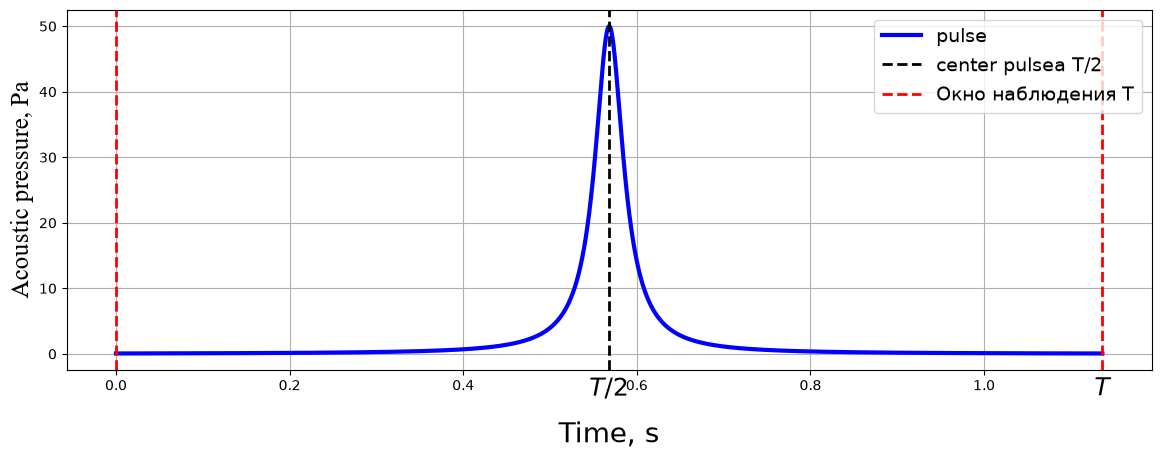

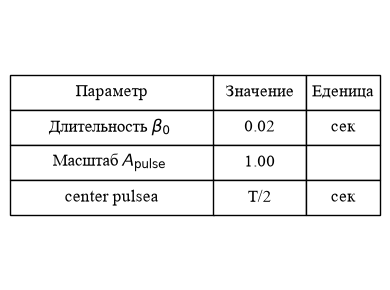

In [70]:
# Построение графика
title_main = "pulseный signal s(t)"
fig, ax = plt.subplots(1, 1, figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.TIME_VECTOR, pulse_signal,
    color="blue", linewidth=3, label="pulse  "
)

# Названия осей и заголовок
ax.set_xlabel("Time, s", labelpad=20, fontsize=20)
ax.set_ylabel("Acoustic pressure, Pa", fontsize=18, fontfamily="Times New Roman")


# center pulseа и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="center pulseа T/2"
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    config_parametrs["duration_all"],
    color="red", linestyle="--", linewidth=2,
    label="Окно наблюдения T"
)
ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=14)

# parametrs под графиком
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"Длительность $\beta_{\mathrm{0}}$ ", f"{comon.BETTA_PULSE:.2f}", "сек"],
    [r"Масштаб $A_{\mathrm{pulse}}$ ", f"{comon.A:.2f}", " "],
    [r"center pulseа", f"T/2", "сек"]]
create_and_save_table(rows, ["Параметр", "Значение", "Еденица"], f"attachment/images/notebook/table_{title_main}")

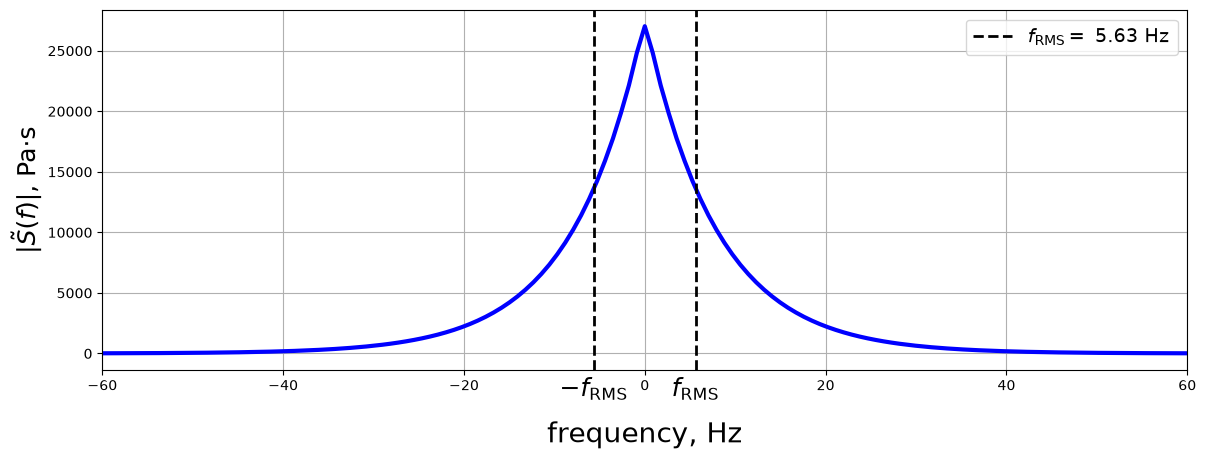

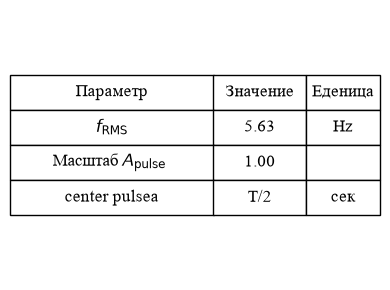

In [71]:


# Построение графика
title_main = "Амплитудный spectrum S(f)"
fig, ax = plt.subplots(1, 1, figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.FREQ_VECTOR, np.abs(spectrum_signal),
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("frequency, Hz", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|\tilde{S}(f)|$, Pa·s", fontsize=18)

# center pulseа и отметки времени


ax.axvline(
    -f_rms_betta,
    color="black", linestyle="--", linewidth=2,
)

ax.axvline(
    f_rms_betta,
    color="black", linestyle="--", linewidth=2,
    label=r"$f_\text{RMS} = $" + f" {f_rms_betta:.2f} Hz"
)

ax.legend(loc="upper right", fontsize=14)
ax.text(
    f_rms_betta, -0.02, r"$f_\text{RMS}$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    -f_rms_betta, -0.02, r"$-f_\text{RMS}$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
# parametrs под графиком

ax.set_xlim(-60,60)

ax.grid(True)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"$f_{\mathrm{RMS}}$",
 f"{f_rms_betta:.2f}", "Hz"],
    [r"Масштаб $A_{\mathrm{pulse}}$ ", f"{comon.A:.2f}", " "],
    [r"center pulseа", f"T/2", "сек"]]
create_and_save_table(rows, ["Параметр", "Значение", "Еденица"], f"attachment/images/notebook/table_{title_main}")

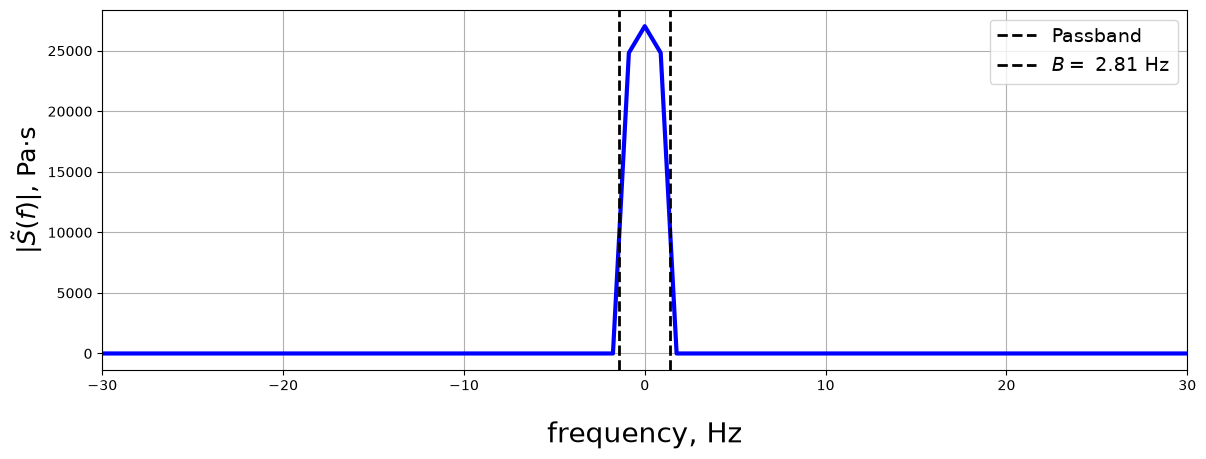

In [72]:


# Построение графика
title_main = "Filtered amplitude spectrum S(f)"
fig, ax = plt.subplots(1, 1, figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.FREQ_VECTOR, np.abs(spectrum_filtering_signal),
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("frequency, Hz", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|\tilde{S}(f)|$, Pa·s", fontsize=18)

# center pulseа и отметки времени


ax.axvline(
    -B/2,
    color="black", linestyle="--", linewidth=2,
    label="Passband"
)

ax.axvline(
    B/2,
    color="black", linestyle="--", linewidth=2,
    label=r"$B  = $" + f" {B:.2f} Hz"
)

ax.legend(loc="upper right", fontsize=14)

# parametrs под графиком

ax.set_xlim(-30,30)

ax.grid(True)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

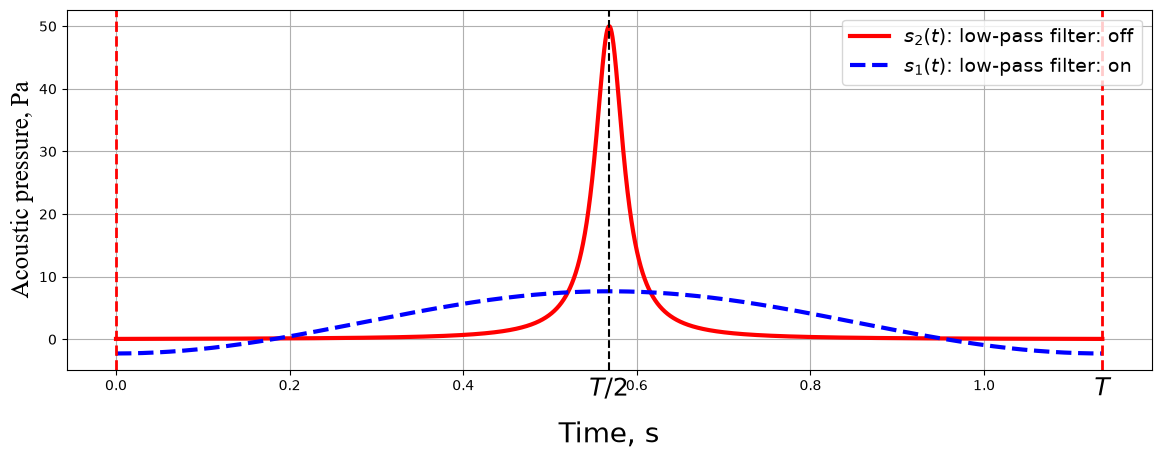

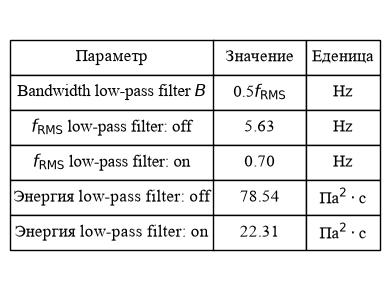

In [73]:


# Построение графика
title_main = "pulseный signal P(t) после фильтрации"
fig, ax = plt.subplots(1, 1, figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.25)

ax.plot(
    cfg.TIME_VECTOR, pulse_signal_copy,
    color="red", linewidth=3, label=r"$s_\text{2}(t)$: low-pass filter: off"
)

ax.plot(
    cfg.TIME_VECTOR, back_signal,
    color="blue", linewidth=3, linestyle="--", label=r"$s_\text{1}(t)$: low-pass filter: on"
)


# Названия осей и заголовок
ax.set_xlabel("Time, s", labelpad=20, fontsize=20)
ax.set_ylabel("Acoustic pressure, Pa", fontsize=18, fontfamily="Times New Roman")


# center pulseа и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=1.5,
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    config_parametrs["duration_all"],
    color="red", linestyle="--", linewidth=2
)
ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=14)

# parametrs под графиком

plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"Bandwidth low-pass filter $B$", f"{K}"+r"$f_{\mathrm{RMS}}$", "Hz"],
    [r"$f_{\mathrm{RMS}}$ low-pass filter: off", f"{f_rms_betta:.2f}", "Hz"],
    [r"$f_{\mathrm{RMS}}$ low-pass filter: on", f"{f_rms_new:.2f}", "Hz"],
    ["Энергия low-pass filter: off", f"{energy_pulse_value:.2f}", r"Па$^2 \cdot$с"],
    ["Энергия low-pass filter: on", f"{energy_filt_pulse_value:.2f}", r"Па$^2 \cdot$с"],
]
create_and_save_table(rows, ["Параметр", "Значение", "Еденица"], f"attachment/images/notebook/table_{title_main}")


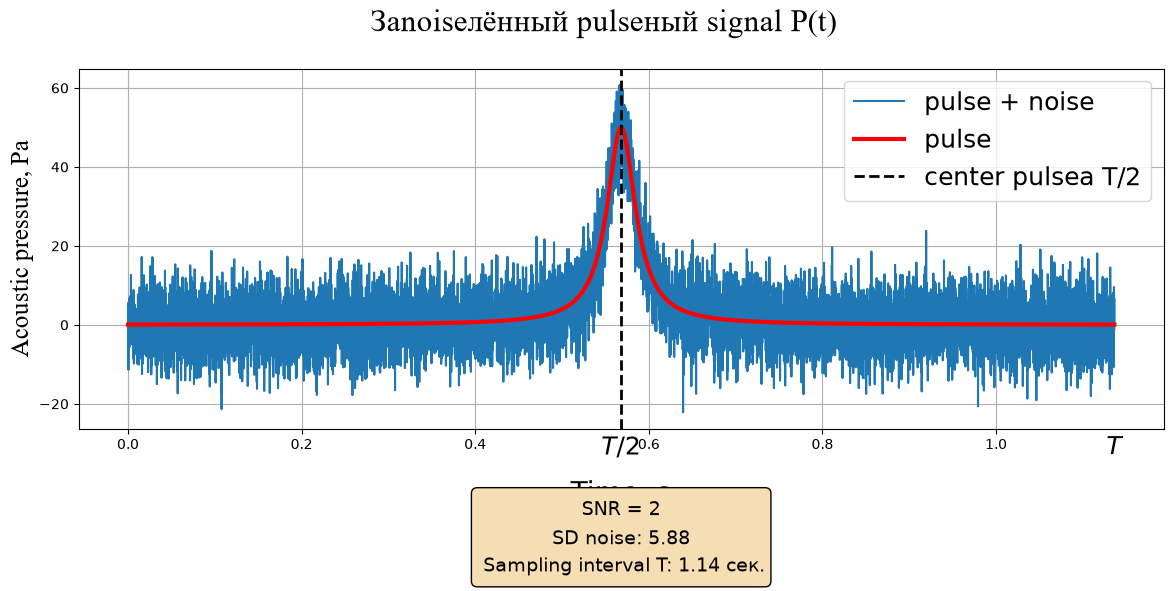

In [74]:
# Построение графика

title_main = "Заnoiseлённый pulseный signal P(t)"

noise = get_noise(config_parametrs, np.random.default_rng(42), en_signal)
noise_level = calculate_noise_level(en_signal, config_parametrs["snr"], config_parametrs["duration_all"])

noise_signal = pulse_signal_copy + noise
fig, ax = plt.subplots(1, 1, figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.25)

ax.plot(cfg.TIME_VECTOR, noise_signal, label="pulse + noise")
ax.plot(
    cfg.TIME_VECTOR, pulse_signal_copy,
    color="red", linewidth=3, label="pulse  "
)

# Названия осей и заголовок
ax.set_xlabel("Time, s", labelpad=20, fontsize=20)
ax.set_ylabel("Acoustic pressure, Pa", fontsize=18, fontfamily="Times New Roman")

fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# center pulseа и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="center pulseа T/2"
)

ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=18)

# parametrs под графиком
info = (
    f"SNR = {comon.SNR}\n"
    f"SD noise: {noise_level:.2f}\n"
    f" Sampling interval T: {config_parametrs['duration_all']:.2f} сек."
    
)

ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

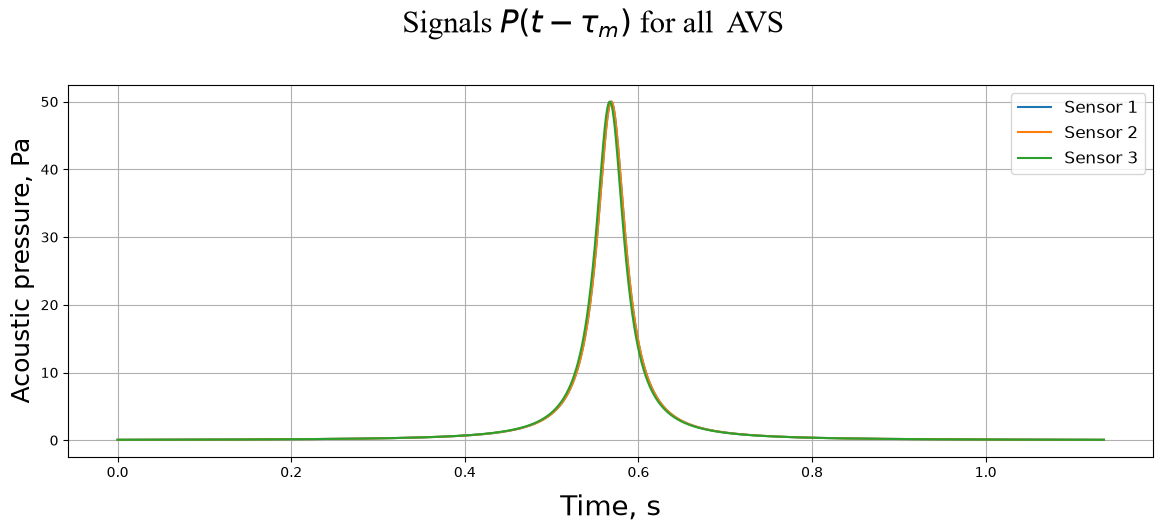

In [75]:
tau_array = get_tau_array(config_parametrs)
params_vector_copy = config_parametrs.copy()

fig, ax = plt.subplots(1, 1, figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.80, bottom=0.18)

# signal на каждом Sensorе
for idx, tau in enumerate(tau_array):
    params_vector_copy["time_vector"] = config_parametrs["time_vector"] - tau
    signal = get_impulse_signal(params_vector_copy)

    ax.plot(
        config_parametrs["time_vector"], signal,
        label=f"Sensor {idx + 1}"
    )

# Названия осей и заголовок
ax.set_xlabel("Time, s", labelpad=10, fontsize=20)
ax.set_ylabel("Acoustic pressure, Pa", fontsize=18)
fig.suptitle(
    r"Signals $P(t-\tau_m)$ for all  AVS",
    y=0.90, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=12)

plt.show()

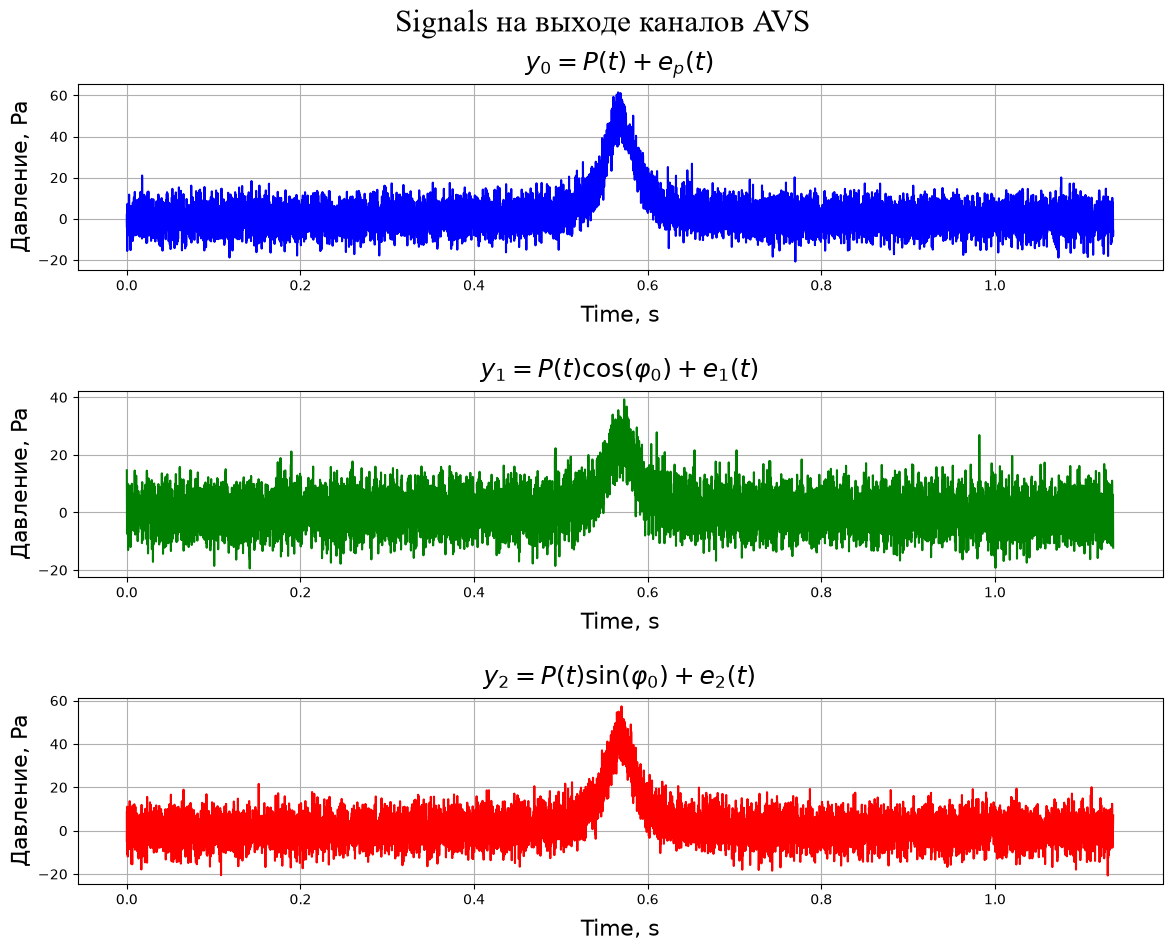

In [76]:
cfg.init_rng()
title_main = r"Signals на выходе каналов AVS"
signals = get_avp_signals(pulse_signal_copy, config_parametrs, energy_pulse_value)

fig, axs = plt.subplots(3, 1, figsize = (14,10))
fig.subplots_adjust(top=0.88, bottom=0.08, hspace=0.65)

fig.suptitle(
    title_main,
    y=0.94, va="center",
    fontfamily="Times New Roman", fontsize=22
)

colors = ("blue", "green", "red")
titles = (
    r"$y_0 = P(t) + e_p(t)$",
    r"$y_1 = P(t)\cos(\varphi_0) + e_1(t)$",
    r"$y_2 = P(t)\sin(\varphi_0) + e_2(t)$"
)

for ax, lambda_values, title, color in zip(axs, signals.values(), titles, colors):
    ax.plot(cfg.TIME_VECTOR, lambda_values, color=color)
    ax.set_xlabel("Time, s", labelpad=8, fontsize=16)
    ax.set_ylabel("Давление, Pa", fontsize=16)
    ax.set_title(title, pad=10, fontsize=18)
    ax.grid(True)
    
plt.savefig(fname = f"attachment/images/notebook/{str(title_main)}", bbox_inches = 'tight', dpi = 300)
plt.show()

In [77]:
channel_matrix = get_channel_matrix(config_parametrs, tau_array, get_impulse_signal)
W = get_covariation_matrix(channel_matrix, comon.N)
dir_matrix = calculate_stiring_matrix(cfg.PHI_VECTOR, comon.M)
E_bar = calculate_bartlett_values(W,dir_matrix)
E_cap = calculate_capon_values(W, dir_matrix)


TypeError: calculate_stiring_matrix() takes 1 positional argument but 2 were given

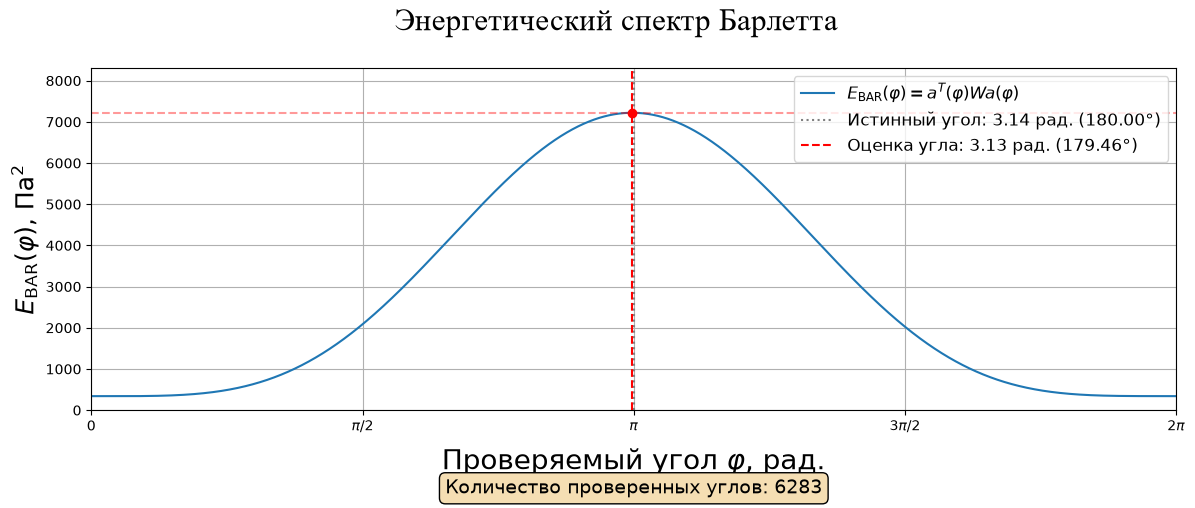

In [ ]:
title_main = "Pseudospectrum Bartlettа"

snr_ratio = comon.SNR
energy_signal = calculate_energy(pulse_signal,cfg.TIME_VECTOR)
sigma_noise = calculate_noise_level(energy_signal, snr_ratio, comon.DURATION_ALL)
phi_0 = comon.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = comon.A

est_phi = get_est_phi(phi_vector, E_bar)
E_max = max(E_bar)
snr_text = (
    "∞ ( )" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f}"
)

fig, ax = plt.subplots(figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Bartlettа и отметки углов
ax.plot(
    phi_vector, E_bar,
    label=r"$E_{\mathrm{BAR}}(\varphi)=a^T(\varphi)W a(\varphi)$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.2f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.2f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Pa$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

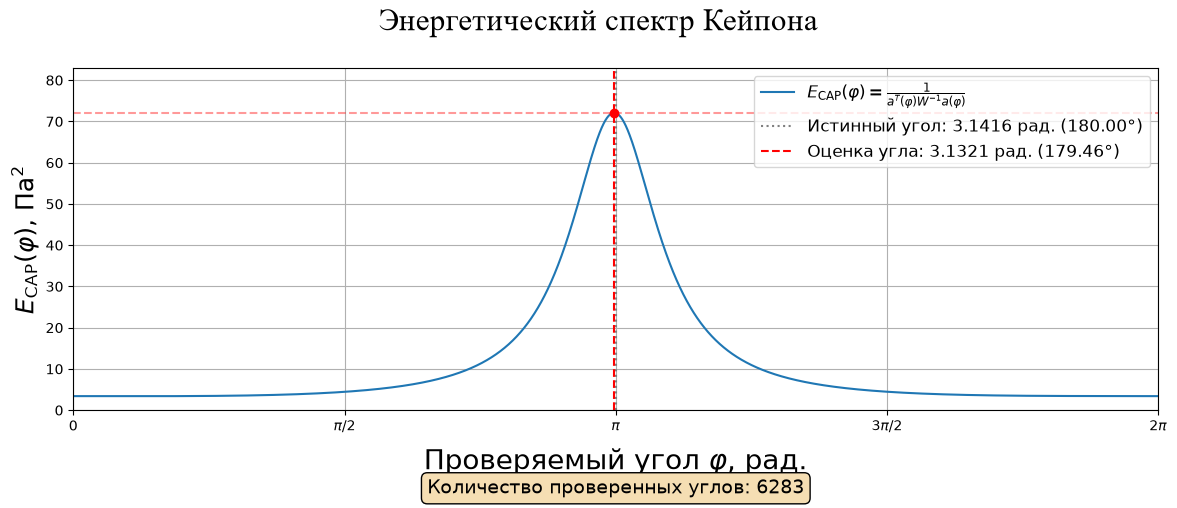

In [ ]:
title_main = "Pseudospectrum Caponа"
snr_ratio = comon.SNR
energy_signal = calculate_energy(pulse_signal,cfg.TIME_VECTOR)
sigma_noise = calculate_noise_level(energy_signal, snr_ratio, comon.DURATION_ALL)
phi_0 = comon.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = comon.A

est_phi = get_est_phi(phi_vector, E_cap)
E_max = max(E_cap)


snr_text = (
    "∞ ( )" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} "
)

fig, ax = plt.subplots(figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Caponа и отметки углов
ax.plot(
    phi_vector, E_cap,
    label=r"$E_{\mathrm{CAP}}(\varphi)=\frac{1}{a^T(\varphi)W^{-1}a(\varphi)}$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.4f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.4f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    "Pseudospectrum Caponа",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{CAP}}(\varphi)$, Pa$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()